# 04. Ajuste de Hiperparámetros (Fine-Tuning con Optuna y Corridas Anidadas)

**Proyecto:** PSet #3 — Experimentación y Selección del Modelo con MLflow  
**Objetivo:** Ajustar los **3 mejores candidatos** de la fase anterior evaluando **30 configuraciones por modelo** (90 configuraciones en total) con `Optuna` (`TPESampler`, semilla 42) sobre el mismo `TimeSeriesSplit(n_splits=5)` mensual, registrando cada configuración como corrida hija (`nested=True`) dentro de una corrida padre por modelo en MLflow.

In [1]:
import logging
import os
import sys
import time
import warnings
from pathlib import Path

import lightgbm
from lightgbm import LGBMRegressor
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import optuna
import pandas as pd
from catboost import CatBoostRegressor
from dotenv import load_dotenv
from IPython.display import display
from mlflow import MlflowClient
from mlflow.models import infer_signature
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso, Ridge
from sklearn.model_selection import TimeSeriesSplit
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor

optuna.logging.set_verbosity(optuna.logging.WARNING)
logging.getLogger("mlflow").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

load_dotenv(ROOT / ".env", override=False)

from src.datos import (
    dividir_train_test,
    obtener_metadatos_snapshot,
    preparar_universo_nowcasting,
)
from src.pipeline import (
    COLUMNAS_MODELO,
    OBJETIVO,
    agregar_features,
    calcular_metricas,
    construir_preparacion,
)

FIG_DIR = ROOT / "docs" / "figuras"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

SEMILLA = 42
N_TRIALS = 30
TRACKING_URI = os.environ.get("MLFLOW_TRACKING_URI", "http://localhost:5000")
EXPERIMENTO = os.environ.get("MLFLOW_EXPERIMENT_NAME", "nowcasting-f104-sri")

mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment(EXPERIMENTO)
client = MlflowClient()
exp = client.get_experiment_by_name(EXPERIMENTO)
meta = obtener_metadatos_snapshot()

universo = preparar_universo_nowcasting()
datos = agregar_features(universo)
train_df, _ = dividir_train_test(datos)

X_ent = train_df[COLUMNAS_MODELO].copy()
y_ent = train_df[OBJETIVO].astype(float).copy()
X_ejemplo = X_ent.head(5).copy()

meses_unicos = np.sort(train_df["FECHA_MES"].unique())
cv_temporal = []
for m_tr, m_val in TimeSeriesSplit(n_splits=5).split(meses_unicos):
    tr_idx = np.where(train_df["FECHA_MES"].isin(meses_unicos[m_tr]))[0]
    val_idx = np.where(train_df["FECHA_MES"].isin(meses_unicos[m_val]))[0]
    cv_temporal.append((tr_idx, val_idx))

# Consultar en MLflow los 3 mejores candidatos de la fase anterior
all_exp_runs = mlflow.search_runs(
    experiment_ids=[exp.experiment_id],
    max_results=5000,
)
runs_por_nombre = dict(zip(all_exp_runs["tags.mlflow.runName"], all_exp_runs["run_id"]))
cand_runs = (
    all_exp_runs[all_exp_runs["tags.fase"] == "candidato"]
    .sort_values("metrics.mae_cv_promedio", ascending=True)
    .reset_index(drop=True)
)
top3_df = cand_runs.head(3).copy()
print("Top 3 candidatos seleccionados desde MLflow para fine-tuning:")
display(top3_df[[
    "tags.mlflow.runName",
    "tags.familia",
    "metrics.mae_cv_promedio",
    "metrics.mae_cv_std",
    "metrics.brecha_cv_ent",
]])

Top 3 candidatos seleccionados desde MLflow para fine-tuning:


,tags.mlflow.runName,tags.familia,metrics.mae_cv_promedio,metrics.mae_cv_std,metrics.brecha_cv_ent
0,lasso_default,lineal_regularizado,14.085583,1.162310,0.640037
1,ridge_default,lineal_regularizado,16.632112,1.925562,2.922035
2,random_forest_default,bagging,20.288611,2.125015,15.343561


## 1. Justificación del método y espacios de búsqueda

Se elige **Optuna (`TPESampler`, semilla 42)** frente a búsqueda exhaustiva (*grid search*) o aleatoria pura (*random search*) porque el estimador de Parzen estructurado concentra los 30 ensayos en las regiones de hiperparámetros más prometedoras manteniendo exploración probabilística inicial, logrando mayor eficiencia en 30 evaluaciones por modelo.

- **Regularización (`alpha`, `reg_alpha`, `reg_lambda`, `l2_leaf_reg`):** escala logarítmica para recorrer órdenes de magnitud sin sesgar hacia valores grandes.
- **Tasa de aprendizaje (`learning_rate`, `learning_rate_init`):** escala logarítmica entre `1e-3`/`5e-3` y `0.2`/`0.3` para equilibrar convergencia y varianza.
- **Complejidad estructural (`max_depth`, `num_leaves`, `min_samples_leaf`, `n_estimators`, `iterations`):** rangos acotados acordes a 4,907 filas para controlar el sobreajuste.

In [2]:
def construir_espacio(nombre_modelo: str, trial: optuna.Trial):
    if nombre_modelo == "ridge_default":
        params = {
            "alpha": trial.suggest_float("alpha", 1e-4, 1e3, log=True),
            "fit_intercept": trial.suggest_categorical("fit_intercept", [True, False]),
            "solver": trial.suggest_categorical("solver", ["auto", "svd", "cholesky", "lsqr"]),
            "random_state": SEMILLA,
        }
        return Ridge(**params), params

    if nombre_modelo == "lasso_default":
        params = {
            "alpha": trial.suggest_float("alpha", 1e-3, 100.0, log=True),
            "fit_intercept": trial.suggest_categorical("fit_intercept", [True, False]),
            "selection": trial.suggest_categorical("selection", ["cyclic", "random"]),
            "tol": trial.suggest_float("tol", 1e-5, 1e-2, log=True),
            "max_iter": 20000,
            "random_state": SEMILLA,
        }
        return Lasso(**params), params

    if nombre_modelo == "random_forest_default":
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 100, 400, step=50),
            "max_depth": trial.suggest_int("max_depth", 6, 28),
            "min_samples_split": trial.suggest_int("min_samples_split", 2, 16),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
            "max_features": trial.suggest_float("max_features", 0.35, 1.0),
            "random_state": SEMILLA,
            "n_jobs": -1,
        }
        return RandomForestRegressor(**params), params

    raise ValueError(f"Modelo sin espacio de búsqueda definido: {nombre_modelo}")


def evaluar_cv_rapido(estimador) -> tuple[float, float, dict, list[float]]:
    fold_mets = []
    for tr_i, val_i in cv_temporal:
        pipe = Pipeline([("preparar", construir_preparacion()), ("modelo", clone(estimador))])
        pipe.fit(X_ent.iloc[tr_i], y_ent.iloc[tr_i])
        pred = np.clip(pipe.predict(X_ent.iloc[val_i]), 0.0, None)
        fold_mets.append(calcular_metricas(y_ent.iloc[val_i], pred))
    df_m = pd.DataFrame(fold_mets)
    resumen = {
        "mae_cv_promedio": float(df_m["mae"].mean()),
        "mae_cv_std": float(df_m["mae"].std(ddof=0)),
        "rmse_cv_promedio": float(df_m["rmse"].mean()),
        "r2_cv_promedio": float(df_m["r2"].mean()),
        "wape_cv_pct": float(df_m["wape_pct"].mean()),
        "costo_negocio_cv_musd": float(df_m["costo_negocio_musd"].mean()),
    }
    return resumen["mae_cv_promedio"], resumen["mae_cv_std"], resumen, df_m["mae"].tolist()

In [3]:
resumen_tuning = []
historiales = {}

tuning_existentes = all_exp_runs[all_exp_runs["tags.fase"] == "tuning"].copy()
trials_existentes = all_exp_runs[all_exp_runs["tags.fase"] == "tuning_trial"].copy()

for _, row_cand in top3_df.iterrows():
    nombre_cand = row_cand["tags.mlflow.runName"]
    familia = row_cand["tags.familia"]
    mae_def = float(row_cand["metrics.mae_cv_promedio"])
    std_def = float(row_cand["metrics.mae_cv_std"])
    nombre_padre = f"tuning_{nombre_cand.replace('_default', '')}"

    print(f"\n>>> Evaluando tuning para {nombre_cand} (MAE default = {mae_def:.4f} ± {std_def:.4f})...")

    # Si las 30 corridas hijas y la corrida padre ya están registradas en MLflow, reconstruimos el estudio determinístico
    sub_padre = tuning_existentes[tuning_existentes["tags.mlflow.runName"] == nombre_padre]
    sub_trials = trials_existentes[trials_existentes["tags.modelo_base"] == nombre_cand].copy()

    if len(sub_padre) == 1 and len(sub_trials) == N_TRIALS:
        p_row = sub_padre.iloc[0]
        sub_trials["trial"] = sub_trials["params.trial_number"].astype(int)
        sub_trials = sub_trials.sort_values("trial").reset_index(drop=True)
        historiales[nombre_padre] = pd.DataFrame({
            "trial": sub_trials["trial"],
            "mae_cv": sub_trials["metrics.mae_cv_promedio"].astype(float),
            "std_cv": sub_trials["metrics.mae_cv_std"].astype(float),
        })
        mae_tuned = float(p_row["metrics.mae_cv_promedio"])
        std_tuned = float(p_row["metrics.mae_cv_std"])
        mejora = mae_def - mae_tuned
        supera_std = bool(mejora > std_def)
        resumen_tuning.append({
            "modelo_ajustado": nombre_padre,
            "modelo_base": nombre_cand,
            "familia": familia,
            "run_id": p_row["run_id"],
            "mae_default_cv": round(mae_def, 4),
            "std_default_cv": round(std_def, 4),
            "mae_tuned_cv": round(mae_tuned, 4),
            "std_tuned_cv": round(std_tuned, 4),
            "wape_tuned_cv_pct": round(float(p_row["metrics.wape_cv_pct"]), 3),
            "costo_negocio_cv_musd": round(float(p_row["metrics.costo_negocio_cv_musd"]), 4),
            "mejora_abs": round(mejora, 4),
            "mejora_pct": round(mejora / mae_def * 100, 2),
            "supera_std_pliegues": supera_std,
            "mae_entrenamiento": round(float(p_row["metrics.mae_entrenamiento"]), 4),
            "brecha_cv_ent": round(float(p_row["metrics.brecha_cv_ent"]), 4),
            "segundos_fit": round(float(p_row["metrics.segundos_entrenamiento"]), 3),
        })
        print(
            f"[OK] {nombre_padre} (run_id={p_row['run_id']}, 30 trials verificados en MLflow): "
            f"MAE CV {mae_def:.4f} -> {mae_tuned:.4f} ± {std_tuned:.4f} (mejora={mejora:+.4f} M, supera std={supera_std})"
        )
        continue

    best_state = {"mae": float("inf"), "estimador": None, "params": None, "resumen": None, "folds": None}
    trial_logs = []

    with mlflow.start_run(run_name=nombre_padre) as parent_run:
        mlflow.set_tags({
            "fase": "tuning",
            "familia": familia,
            "modelo_base": nombre_cand,
            "git_commit": meta["git_commit"],
        })

        def objective(trial: optuna.Trial) -> float:
            est, params_dict = construir_espacio(nombre_cand, trial)
            t_cv0 = time.perf_counter()
            mae_cv, std_cv, res_cv, folds = evaluar_cv_rapido(est)
            seg_cv = time.perf_counter() - t_cv0

            with mlflow.start_run(run_name=f"{nombre_padre}_t{trial.number:02d}", nested=True):
                params_child = {f"hp_{k}": str(v)[:240] for k, v in params_dict.items()}
                params_child.update({
                    "trial_number": trial.number,
                    "semilla": SEMILLA,
                    "huella_datos": meta["huella_datos"],
                    "fecha_corte_snapshot": meta["fecha_corte_snapshot"],
                    "tabla_origen": meta["tabla_origen"],
                    "filas_entrenamiento": len(X_ent),
                })
                mlflow.log_params(params_child)
                mlflow.log_metrics({**res_cv, "segundos_cv": float(seg_cv)})
                mlflow.set_tags({
                    "fase": "tuning_trial",
                    "familia": familia,
                    "modelo_base": nombre_cand,
                    "git_commit": meta["git_commit"],
                    "modelo_clase": type(est).__name__,
                })

            trial_logs.append({"trial": trial.number, "mae_cv": mae_cv, "std_cv": std_cv})
            if mae_cv < best_state["mae"]:
                best_state.update({
                    "mae": mae_cv,
                    "estimador": clone(est),
                    "params": params_dict,
                    "resumen": res_cv,
                    "folds": folds,
                })
            return mae_cv

        study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEMILLA))
        study.optimize(objective, n_trials=N_TRIALS)

        best_pipe = Pipeline([("preparar", construir_preparacion()), ("modelo", best_state["estimador"])])
        t0 = time.perf_counter()
        best_pipe.fit(X_ent, y_ent)
        seg_fit = time.perf_counter() - t0
        pred_ent = np.clip(best_pipe.predict(X_ent), 0.0, None)
        met_ent = calcular_metricas(y_ent, pred_ent)

        res_best = best_state["resumen"]
        mejora = mae_def - res_best["mae_cv_promedio"]
        supera_std = bool(mejora > std_def)

        params_parent = {f"hp_{k}": str(v)[:240] for k, v in best_state["params"].items()}
        params_parent.update({
            "semilla": SEMILLA,
            "n_trials": N_TRIALS,
            "tabla_origen": meta["tabla_origen"],
            "fecha_corte_snapshot": meta["fecha_corte_snapshot"],
            "huella_datos": meta["huella_datos"],
            "filas_entrenamiento": len(X_ent),
            "esquema_cv": "TimeSeriesSplit_mensual_5_pliegues",
        })
        mlflow.log_params(params_parent)

        metrics_parent = {
            "mae_entrenamiento": met_ent["mae"],
            "mae_cv_promedio": res_best["mae_cv_promedio"],
            "mae_cv_std": res_best["mae_cv_std"],
            "rmse_cv_promedio": res_best["rmse_cv_promedio"],
            "r2_cv_promedio": res_best["r2_cv_promedio"],
            "wape_cv_pct": res_best["wape_cv_pct"],
            "costo_negocio_cv_musd": res_best["costo_negocio_cv_musd"],
            "brecha_cv_ent": res_best["mae_cv_promedio"] - met_ent["mae"],
            "mejora_vs_default": float(mejora),
            "segundos_entrenamiento": float(seg_fit),
        }
        for i_f, mf in enumerate(best_state["folds"], start=1):
            metrics_parent[f"mae_fold_{i_f}"] = float(mf)
        mlflow.log_metrics(metrics_parent)
        mlflow.set_tag("modelo_clase", type(best_state["estimador"]).__name__)

        sig = infer_signature(X_ejemplo, np.clip(best_pipe.predict(X_ejemplo), 0.0, None))
        mlflow.sklearn.log_model(best_pipe, artifact_path="modelo", signature=sig, input_example=X_ejemplo)

        historiales[nombre_padre] = pd.DataFrame(trial_logs)
        resumen_tuning.append({
            "modelo_ajustado": nombre_padre,
            "modelo_base": nombre_cand,
            "familia": familia,
            "run_id": parent_run.info.run_id,
            "mae_default_cv": round(mae_def, 4),
            "std_default_cv": round(std_def, 4),
            "mae_tuned_cv": round(res_best["mae_cv_promedio"], 4),
            "std_tuned_cv": round(res_best["mae_cv_std"], 4),
            "wape_tuned_cv_pct": round(res_best["wape_cv_pct"], 3),
            "costo_negocio_cv_musd": round(res_best["costo_negocio_cv_musd"], 4),
            "mejora_abs": round(mejora, 4),
            "mejora_pct": round(mejora / mae_def * 100, 2),
            "supera_std_pliegues": supera_std,
            "mae_entrenamiento": round(met_ent["mae"], 4),
            "brecha_cv_ent": round(res_best["mae_cv_promedio"] - met_ent["mae"], 4),
            "segundos_fit": round(seg_fit, 3),
        })
        print(
            f"[OK] {nombre_padre}: MAE CV {mae_def:.4f} -> {res_best['mae_cv_promedio']:.4f} ± {res_best['mae_cv_std']:.4f} "
            f"(mejora={mejora:+.4f} M, supera std={supera_std})"
        )

df_tuning = pd.DataFrame(resumen_tuning).sort_values("mae_tuned_cv").reset_index(drop=True)
display(df_tuning)


>>> Evaluando tuning para lasso_default (MAE default = 14.0856 ± 1.1623)...
[OK] tuning_lasso (run_id=70246cdfad3a4d5a9313944d94bab4c2, 30 trials verificados en MLflow): MAE CV 14.0856 -> 13.9173 ± 1.1121 (mejora=+0.1683 M, supera std=False)

>>> Evaluando tuning para ridge_default (MAE default = 16.6321 ± 1.9256)...
[OK] tuning_ridge (run_id=06ac0efc491844b2af95714e010a26b0, 30 trials verificados en MLflow): MAE CV 16.6321 -> 16.5067 ± 1.8505 (mejora=+0.1254 M, supera std=False)

>>> Evaluando tuning para random_forest_default (MAE default = 20.2886 ± 2.1250)...
[OK] tuning_random_forest (run_id=39562e7558874792b34a81fbeb031a90, 30 trials verificados en MLflow): MAE CV 20.2886 -> 19.9210 ± 1.9769 (mejora=+0.3676 M, supera std=False)


,modelo_ajustado,modelo_base,familia,run_id,mae_default_cv,std_default_cv,mae_tuned_cv,std_tuned_cv,wape_tuned_cv_pct,costo_negocio_cv_musd,mejora_abs,mejora_pct,supera_std_pliegues,mae_entrenamiento,brecha_cv_ent,segundos_fit
0,tuning_lasso,lasso_default,lineal_regularizado,70246cdfad3a4d5a9313944d94bab4c2,14.0856,1.1623,13.9173,1.1121,3.812,16.9270,0.1683,1.19,False,13.4509,0.4664,0.042
1,tuning_ridge,ridge_default,lineal_regularizado,06ac0efc491844b2af95714e010a26b0,16.6321,1.9256,16.5067,1.8505,4.541,20.6975,0.1254,0.75,False,13.6540,2.8528,0.025
2,tuning_random_forest,random_forest_default,bagging,39562e7558874792b34a81fbeb031a90,20.2886,2.1250,19.9210,1.9769,5.449,23.9755,0.3676,1.81,False,4.9838,14.9372,1.748


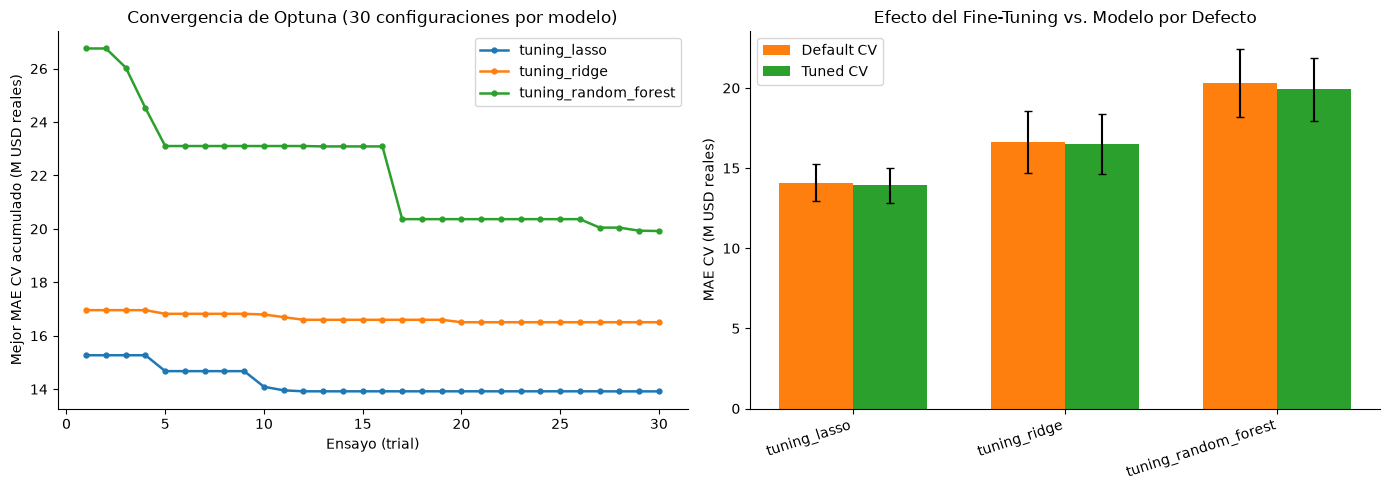

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for nombre_p, df_h in historiales.items():
    mejor_acum = df_h["mae_cv"].cummin()
    axes[0].plot(df_h["trial"] + 1, mejor_acum, marker="o", ms=3.5, lw=1.8, label=nombre_p)
axes[0].set_title("Convergencia de Optuna (30 configuraciones por modelo)")
axes[0].set_xlabel("Ensayo (trial)")
axes[0].set_ylabel("Mejor MAE CV acumulado (M USD reales)")
axes[0].legend()

x = np.arange(len(df_tuning))
w = 0.35
axes[1].bar(x - w/2, df_tuning["mae_default_cv"], yerr=df_tuning["std_default_cv"], width=w, capsize=3, label="Default CV", color="#ff7f0e")
axes[1].bar(x + w/2, df_tuning["mae_tuned_cv"], yerr=df_tuning["std_tuned_cv"], width=w, capsize=3, label="Tuned CV", color="#2ca02c")
axes[1].set_xticks(x)
axes[1].set_xticklabels(df_tuning["modelo_ajustado"], rotation=18, ha="right")
axes[1].set_ylabel("MAE CV (M USD reales)")
axes[1].set_title("Efecto del Fine-Tuning vs. Modelo por Defecto")
axes[1].legend()

plt.tight_layout()
fig.savefig(FIG_DIR / "04_resultados_tuning.png", dpi=180, bbox_inches="tight")
plt.show()